In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hospital_readmission_dataset.csv to hospital_readmission_dataset.csv


In [ ]:
df = pd.read_csv("hospital_readmission_dataset.csv")

print(df.head())

   patient_id  age  gender diagnosis_code  heart_rate  systolic_bp  \
0           1   69    Male            C50          91          128   
1           2   32    Male            A41         102          153   
2           3   89  Female            K21          84          105   
3           4   78    Male            E11          70          130   
4           5   38    Male            J44          79          120   

   oxygen_saturation  prior_visits  length_of_stay  diabetes  hypertension  \
0               94.8             3             5.2         1             0   
1               99.6             3             1.6         1             0   
2               98.4             2             3.9         0             0   
3              100.0             2             1.0         1             0   
4               97.3             2             3.7         1             0   

   previous_readmission  readmitted_30d  
0                     0               1  
1                     1   

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
print(df.info())

Dataset Shape: (1000, 13)

Column Names:
Index(['patient_id', 'age', 'gender', 'diagnosis_code', 'heart_rate',
       'systolic_bp', 'oxygen_saturation', 'prior_visits', 'length_of_stay',
       'diabetes', 'hypertension', 'previous_readmission', 'readmitted_30d'],
      dtype='object')

Missing Values:
patient_id              0
age                     0
gender                  0
diagnosis_code          0
heart_rate              0
systolic_bp             0
oxygen_saturation       0
prior_visits            0
length_of_stay          0
diabetes                0
hypertension            0
previous_readmission    0
readmitted_30d          0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   patient_id            1000 non-null   int64  
 1   age                   1000 non-null   int64  
 2   gender 

In [ ]:
print(df["readmitted_30d"].value_counts())

print("\nPercentage:")
print(df["readmitted_30d"].value_counts(normalize=True) * 100)

readmitted_30d
0    742
1    258
Name: count, dtype: int64

Percentage:
readmitted_30d
0    74.2
1    25.8
Name: proportion, dtype: float64


In [ ]:
X = df.drop(columns=["patient_id", "readmitted_30d"])
y = df["readmitted_30d"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   age  gender diagnosis_code  heart_rate  systolic_bp  oxygen_saturation  \
0   69    Male            C50          91          128               94.8   
1   32    Male            A41         102          153               99.6   
2   89  Female            K21          84          105               98.4   
3   78    Male            E11          70          130              100.0   
4   38    Male            J44          79          120               97.3   

   prior_visits  length_of_stay  diabetes  hypertension  previous_readmission  
0             3             5.2         1             0                     0  
1             3             1.6         1             0                     1  
2             2             3.9         0             0                     0  
3             2             1.0         1             0                     0  
4             2             3.7         1             0                     0  

Target:
0    1
1    0
2    1
3    0
4    0
Nam

In [ ]:
numeric_features = [
    "age",
    "heart_rate",
    "systolic_bp",
    "oxygen_saturation",
    "prior_visits",
    "length_of_stay",
    "diabetes",
    "hypertension",
    "previous_readmission"
]

categorical_features = [
    "gender",
    "diagnosis_code"
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            penalty="l2",
            C=1.0,
            max_iter=1000
        ))
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted Classes:")
print(y_pred[:10])

print("\nPredicted Probabilities:")
print(y_prob[:10])

Predicted Classes:
[0 0 0 0 0 0 0 0 0 0]

Predicted Probabilities:
[0.12601771 0.32533171 0.19682776 0.16134405 0.27990366 0.04708849
 0.05576702 0.08597496 0.2680211  0.38356527]


In [ ]:
auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.6251299376299376


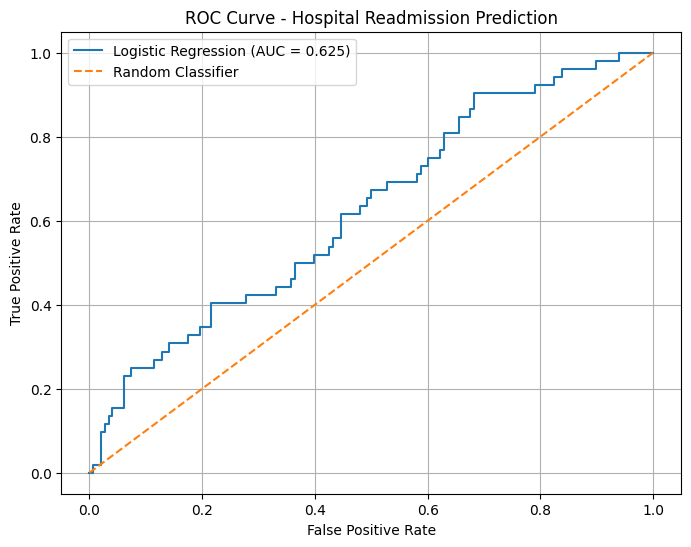

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Hospital Readmission Prediction")
plt.legend()
plt.grid()

plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[138  10]
 [ 40  12]]


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Readmission", "Readmission"]
))

                precision    recall  f1-score   support

No Readmission       0.78      0.93      0.85       148
   Readmission       0.55      0.23      0.32        52

      accuracy                           0.75       200
     macro avg       0.66      0.58      0.59       200
  weighted avg       0.72      0.75      0.71       200



In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)

True Negatives : 138
False Positives: 10
False Negatives: 40
True Positives  : 12


In [ ]:
auc = roc_auc_score(y_test, y_prob)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

In [ ]:
print("========================================")
print("HOSPITAL READMISSION PREDICTION")
print("========================================")

print(f"ROC-AUC Score: {auc:.3f}")

print("\nConfusion Matrix:")

print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nModel: Logistic Regression")
print("Regularization: L2")

HOSPITAL READMISSION PREDICTION
ROC-AUC Score: 0.625

Confusion Matrix:
True Negatives : 138
False Positives: 10
False Negatives: 40
True Positives : 12

Model: Logistic Regression
Regularization: L2
